# Learning an Epitrochoid with a Running Mean

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GalacticDynamics/phasecurvefit/blob/main/docs/tutorials/epitrochoid_runningmean.ipynb)

This tutorial fits the same self-intersecting epitrochoid as the
[epitrochoid autoencoder tutorial](epitrochoid_autoencoder.ipynb), with one change:
the mean path comes from a **running mean** instead of a trained decoder network.

The running mean has nothing to train. For any ordering coordinate $\gamma$, it
averages the positions of the member stars whose $\gamma$ falls within a small
window around it. Only the encoder is trained, which makes this approach much
faster: useful when the fit sits inside a loop, such as a likelihood evaluated at
every step of an MCMC.

The price is accuracy. The final figure shows the running-mean path sitting
visibly *inside* the curve, and the last section explains why and how the window
size controls it.

In [1]:
import equinox as eqx
import jax
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np

import quaxed.numpy as jnp
import unxt as u

import phasecurvefit as pcf

In [2]:
key = jr.key(201030)

## Data: Self-Intersecting Epitrochoid Curve

We build a single stream that self-intersects using an **epitrochoid curve** that traces one continuous loop from 5° to 355°, leaving a 10° gap so the curve doesn't close back on itself. The epitrochoid's internal structure (5 loops within one outer rotation) creates multiple self-intersections along the path.

At the crossings, a purely spatial walk can jump to the other branch: the nearest neighbour may lie on a different strand. Including velocities in the distance fixes this: the strands cross in position but move in different directions, so with `FullPhaseSpaceDistanceMetric` (where `metric_scale`, a time, converts a velocity difference into an equivalent distance) a star on the other strand is far away in phase space, and the walk stays on its own strand.

The curve is parameterized by a scalar `t`, which we keep as ground truth but never show to the ordering.

In [3]:
usys = u.unitsystems.si

In [4]:
def make_self_intersecting_stream(
    key,
    *,
    n: int,
    noise_sigma=0.5,
    scale=120.0,
    R: float = 5.0,
    r: float = 1.0,
    d: float = 4.5,
):
    """Return (t, pos, vel) for an OPEN curve with self-intersections."""
    # Epitrochoid parameters: ratio=5 means 5 internal loops per outer rotation

    # Single outer rotation: 5° to 355° with 10° gap
    t_start = 5.0 * jnp.pi / 180.0
    t_end = 355.0 * jnp.pi / 180.0
    t = jnp.linspace(t_start, t_end, n)

    ratio = (R + r) / r  # = 5 internal rotations per outer rotation
    x0 = scale * ((R + r) * jnp.cos(t) - d * jnp.cos(ratio * t)) / 5.0
    y0 = scale * ((R + r) * jnp.sin(t) - d * jnp.sin(ratio * t)) / 5.0

    # Derivatives for velocity
    dx0 = scale * (-(R + r) * jnp.sin(t) + d * ratio * jnp.sin(ratio * t)) / 5.0
    dy0 = scale * ((R + r) * jnp.cos(t) - d * ratio * jnp.cos(ratio * t)) / 5.0

    # Optional small positional noise
    kx, ky = jr.split(key)
    x = x0 + noise_sigma * jr.normal(kx, (n,))
    y = y0 + noise_sigma * jr.normal(ky, (n,))

    # Pack into unitful quantities
    pos = {"x": u.Q(x, usys["length"]), "y": u.Q(y, usys["length"])}
    vel = {"x": u.Q(dx0, usys["speed"]), "y": u.Q(dy0, usys["speed"])}
    return t, pos, vel

In [5]:
key, subkey = jr.split(key)
t, pos, vel = make_self_intersecting_stream(
    subkey,
    n=2048,
    noise_sigma=6,
)

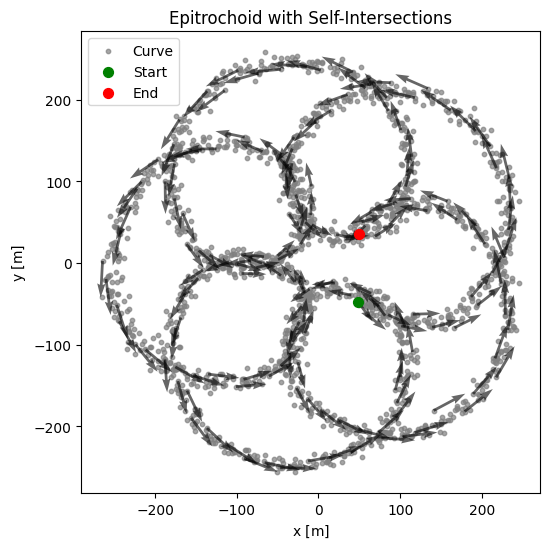

In [6]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(pos["x"], pos["y"], label="Curve", color="gray", alpha=0.7, s=10)

# Add velocity arrows every 10th point
every = 12
ax.quiver(
    np.array(pos["x"][::every]),
    np.array(pos["y"][::every]),
    np.array(vel["x"][::every]),
    np.array(vel["y"][::every]),
    scale=10_000,
    width=0.006,
    alpha=0.6,
    color="black",
)

ax.scatter(pos["x"][:1], pos["y"][:1], label="Start", color="green", s=50)
ax.scatter(pos["x"][-1:], pos["y"][-1:], label="End", color="red", s=50)
ax.legend()
ax.set(
    aspect="equal",
    title="Epitrochoid with Self-Intersections",
    xlabel=f"x [{ax.get_xlabel()}]",
    ylabel=f"y [{ax.get_ylabel()}]",
)
plt.show();

In [7]:
# Shuffle the data
key, subkey = jr.split(key)
order = jr.permutation(subkey, jnp.arange(len(t)))

qs = jax.tree.map(lambda x: x[order], pos)
ps = jax.tree.map(lambda x: x[order], vel)

In [8]:
# Determine the starting index as the point closest to the starting point
start_idx = int(np.argsort(order)[0])

# Walk configuration
config = pcf.WalkConfig(
    strategy=pcf.strats.KDTree(k=60),
    metric=pcf.metrics.FullPhaseSpaceDistanceMetric(),
)
metric_scale = u.Q(4, "s")
max_dist = u.Q(40, "m")

# Perform walk
walkresult = pcf.order(
    qs,
    ps,
    pcf.orderers.LocalFlowOrderer(
        start_idx=start_idx,
        metric_scale=metric_scale,
        max_dist=max_dist,
        config=config,
        direction="forward",
    ),
    metadata=pcf.StateMetadata(usys=usys),
)

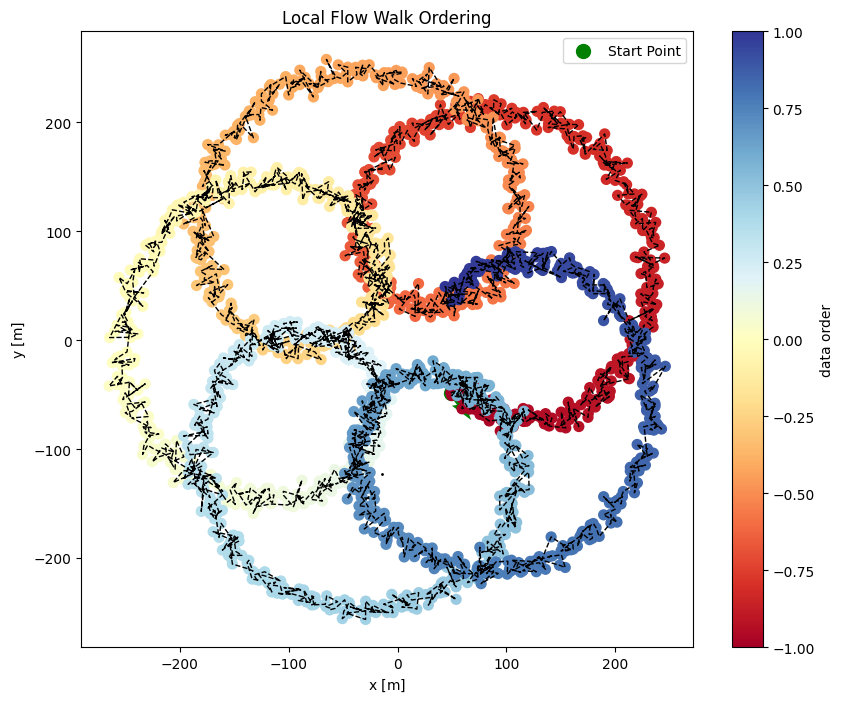

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
im = ax.scatter(qs["x"], qs["y"], s=1, c="k")

ax.scatter(
    np.array(qs["x"][start_idx])[None],
    np.array(qs["y"][start_idx])[None],
    c="green",
    s=100,
    label="Start Point",
)
ax.quiver(
    np.array(qs["x"][start_idx])[None],
    np.array(qs["y"][start_idx])[None],
    np.array(ps["x"][start_idx])[None],
    np.array(ps["y"][start_idx])[None],
    color="green",
)

ordering = walkresult.ordering
walk_qs = {k: v[ordering] for k, v in walkresult.positions.items()}
timeline = np.linspace(-1, 1, len(ordering))
im = ax.scatter(walk_qs["x"], walk_qs["y"], s=50, c=timeline, cmap="RdYlBu")
ax.plot(walk_qs["x"], walk_qs["y"], c="k", lw=1, ls="--")

plt.colorbar(im, ax=ax, label="data order")

ax.set(
    aspect="equal",
    xlabel=f"x [{ax.get_xlabel()}]",
    ylabel=f"y [{ax.get_ylabel()}]",
    title="Local Flow Walk Ordering",
)
plt.legend()
plt.show();

**What to look for:** the dashed line should follow one strand at a time
through every crossing, without jumping to the strand it crosses.

## Training the encoder; building the running mean

`EncoderExternalDecoder` pairs a trainable encoder with a decoder that is *not* a
network:

- The **encoder** (`OrderingNet`) maps each star's position and velocity to an
  ordering coordinate $\gamma$ and a membership probability $p$. It is trained on
  the walk's ordering, exactly as in phase 1 of the full autoencoder.
- The **decoder** (`RunningMeanDecoder`) is filled in once training finishes. It
  stores every star's encoder $\gamma$ and position, and answers a query $\gamma$
  with the mean position of the member stars ($p > 0.5$) within `window_size / 2`
  of it. Here $\gamma$ runs from 0 to 1, so `window_size=0.05` averages over 5% of
  the curve's length.

`in_size=4` is the number of phase-space coordinates: 2 positions + 2 velocities.

In [10]:
key, model_key, train_key = jr.split(key, 3)
normalizer = pcf.nn.StandardScalerNormalizer(qs, ps)
model = pcf.nn.EncoderExternalDecoder(
    encoder=pcf.nn.OrderingNet(in_size=4, key=model_key),
    decoder=pcf.nn.RunningMeanDecoder(window_size=0.05),
    normalizer=normalizer,
)
result, opt_state, losses = pcf.nn.train_autoencoder(model, walkresult, key=train_key)

Training:   0%|          | 0/800 [00:00<?, ?epoch/s]

Only the encoder trains, so the loss curve has a single phase with a single
objective (compare the three-phase curve in the
[stream autoencoder tutorial](stream_autoencoder.ipynb)).

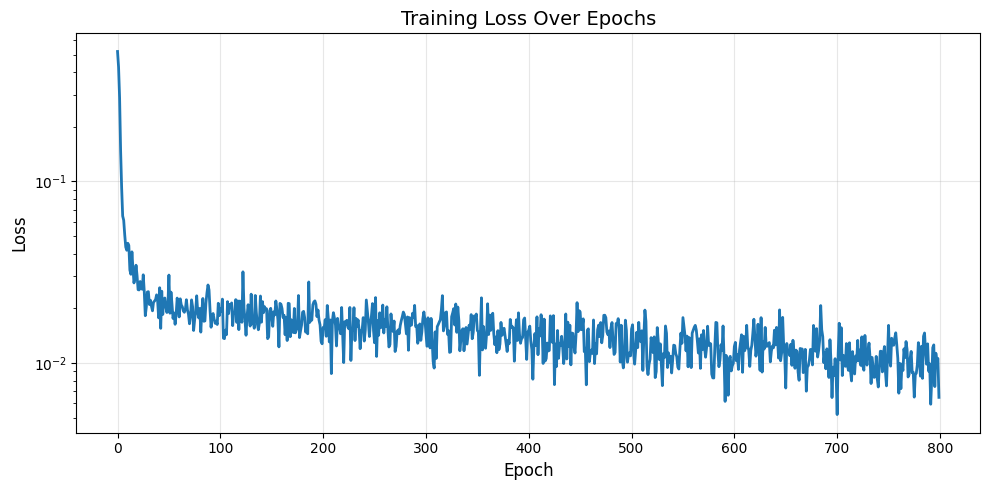

Final loss: 0.006462


In [11]:
# Plot training losses
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(np.asarray(losses), linewidth=2)
ax.set_xlabel("Epoch", fontsize=12)
ax.set_ylabel("Loss", fontsize=12)
ax.set_title("Training Loss Over Epochs", fontsize=14)
ax.set_yscale("log")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print(f"Final loss: {losses[-1]:.6f}")

## Result

In [12]:
def running_mean_path(result, window_size, n=2_000):
    """Evaluate the running-mean path with a given window, away from the tips.

    Within half a window of either end the window is one-sided, so we stop there.
    """
    result_w = eqx.tree_at(lambda r: r.model.decoder.window_size, result, window_size)
    g_train = result_w.model.decoder.gamma_train
    lo = float(g_train.min()) + window_size / 2
    hi = float(g_train.max()) - window_size / 2
    return result_w(jnp.linspace(lo, hi, n))

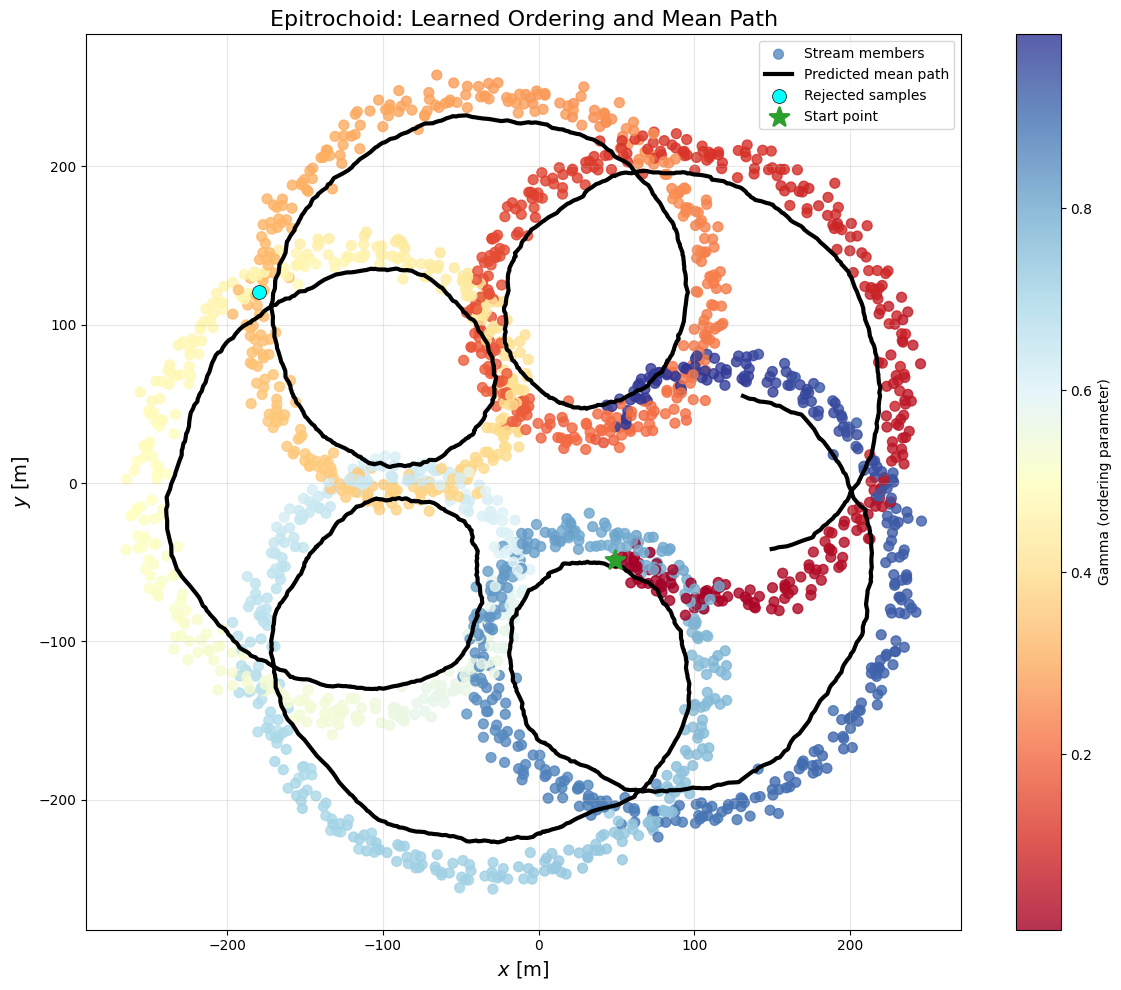

In [13]:
fig, ax = plt.subplots(figsize=(12, 10))

all_gamma, all_probs = result.model.encode(result.positions, result.velocities)
rejected_membership = all_probs < 0.5  # the running mean's member threshold
qs_pred = running_mean_path(result, window_size=0.05)

# Plot all points with gradient coloring
im = ax.scatter(
    np.asarray(qs["x"]),
    np.asarray(qs["y"]),
    s=50,
    c=np.asarray(all_gamma),
    cmap="RdYlBu",
    alpha=0.8,
    label="Stream members",
)

# Plot predicted mean path
ax.plot(
    np.asarray(qs_pred["x"]),
    np.asarray(qs_pred["y"]),
    c="k",
    lw=3,
    label="Predicted mean path",
)

# Mark rejected samples in cyan
ax.scatter(
    np.asarray(qs["x"][rejected_membership]),
    np.asarray(qs["y"][rejected_membership]),
    s=100,
    c="cyan",
    alpha=1.0,
    marker="o",
    edgecolors="black",
    linewidths=0.5,
    label="Rejected samples",
)

# Mark start point
ax.scatter(
    np.asarray(qs["x"][start_idx]),
    np.asarray(qs["y"][start_idx]),
    s=200,
    c="tab:green",
    marker="*",
    label="Start point",
    linewidths=2,
    zorder=5,
)

ax.set_xlabel(r"$x$ [m]", fontsize=14)
ax.set_ylabel(r"$y$ [m]", fontsize=14)
ax.set_title("Epitrochoid: Learned Ordering and Mean Path", fontsize=16)
fig.colorbar(im, ax=ax, label="Gamma (ordering parameter)")
ax.legend(loc="upper right", fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show();

**What to look for:** the colour (the encoder's $\gamma$) should change
smoothly along the curve, and the path should follow every loop. It does, but it
runs visibly *inside* the stars, most of all around the tight inner loops.

## Why is the running-mean path offset?

The offset is built into averaging along a curve. The stars within one window lie
on a short arc, and the average of points on an arc sits on the inside of the
bend, not on the arc itself. The more the arc bends within the window, the further
inside its average falls. The inward pull therefore grows with:

- **the window size**: a wider window spans a longer, more strongly bent arc, and
- **the curvature**: the tight inner loops of the epitrochoid pull the path in far
  more than the gently curving outer arcs.

Shrinking the window reduces the offset, but only up to a point: a smaller window
averages over fewer stars, so the path starts to follow the noise in individual
stars instead. The running mean doesn't need to be retrained to try a different
window, so we can compare several directly.

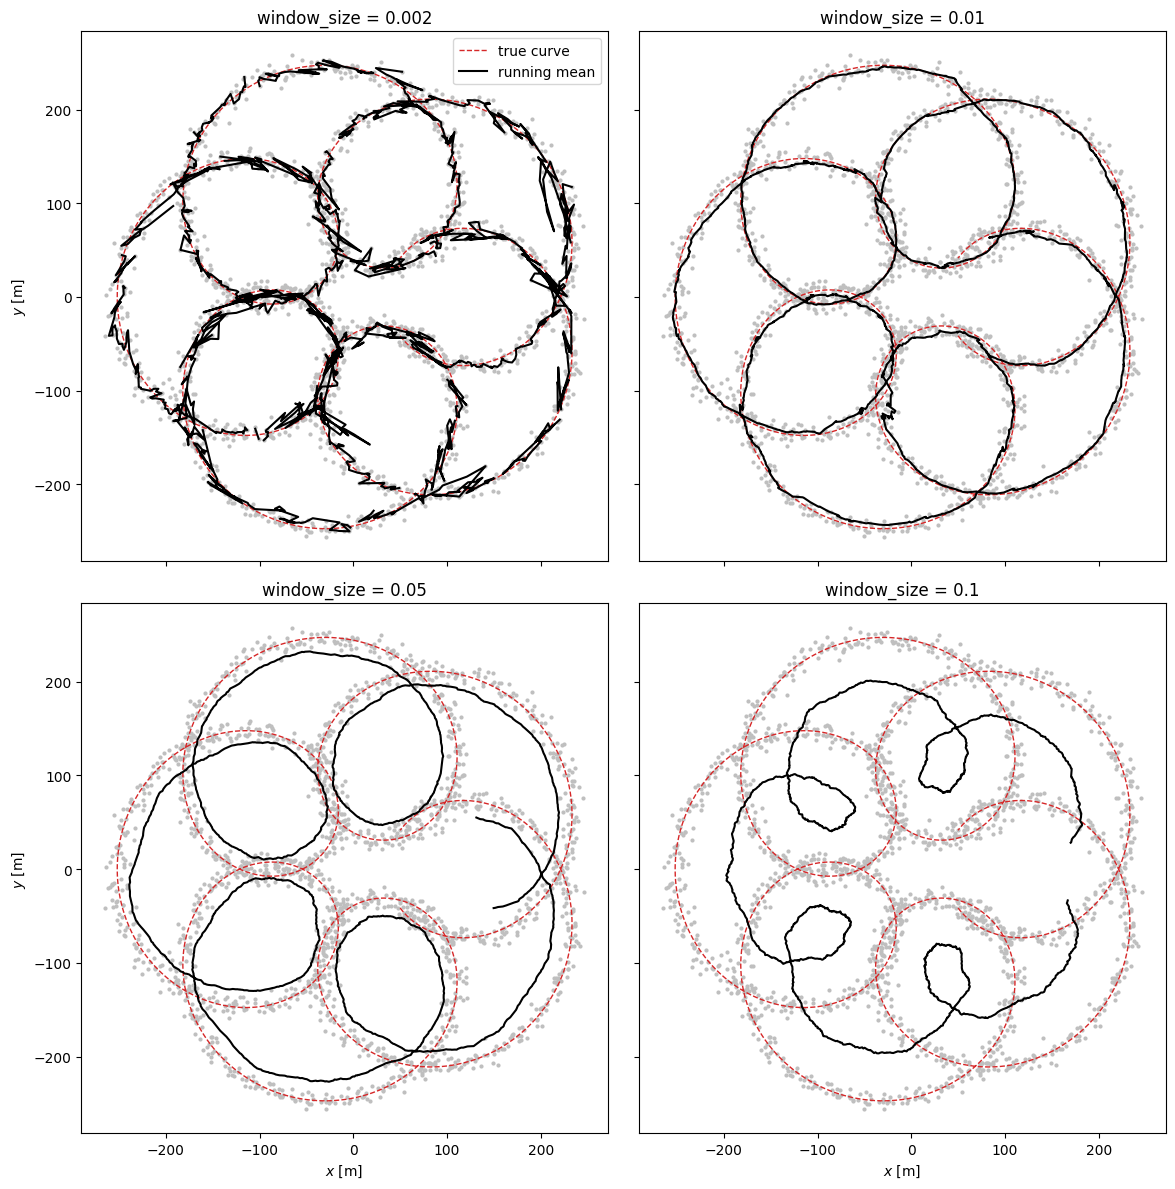

In [14]:
# The true curve, without noise, for reference.
_, pos_true, _ = make_self_intersecting_stream(key, n=4_000, noise_sigma=0)

window_sizes = [0.002, 0.01, 0.05, 0.1]
fig, axs = plt.subplots(2, 2, figsize=(12, 12), sharex=True, sharey=True)
for ax, w in zip(axs.flat, window_sizes, strict=True):
    path = running_mean_path(result, w)
    ax.scatter(qs["x"], qs["y"], s=4, c="0.75")
    ax.plot(
        pos_true["x"], pos_true["y"], c="tab:red", lw=1, ls="--", label="true curve"
    )
    ax.plot(path["x"], path["y"], c="k", lw=1.5, label="running mean")
    ax.set(aspect="equal", title=f"window_size = {w}")
axs[0, 0].legend(loc="upper right")
for ax in axs[1]:
    ax.set_xlabel(r"$x$ [m]")
for ax in axs[:, 0]:
    ax.set_ylabel(r"$y$ [m]")
plt.tight_layout()
plt.show()

With the smallest window (about four stars per window) the path is jagged: it
chases the noise. Worse, some windows contain no member stars at all. The running
mean then has nothing to average and returns NaN, which shows up as gaps in the
path. (`RunningMeanDecoder(..., empty_window="nearest")` instead falls back to the
member stars nearest in $\gamma$.) At `0.01` the path tracks the true curve closely. At `0.05`, the value
used above, it cuts inside the inner loops, and at `0.1` it misses them badly.

A good window is small compared with the tightest bend in the curve, but still
holds enough stars to average away their scatter. Where that balance falls
depends on the curve's shape and how densely it is sampled, so it needs choosing
for each dataset. A trained decoder, as in the
[epitrochoid autoencoder tutorial](epitrochoid_autoencoder.ipynb), doesn't face
this trade-off: it fits a smooth curve *through* the stars. That is what the
extra training time buys.

**The tips.** The window is a hard cut in $\gamma$. Within half a window of
either end there are stars on one side only, so the average is pulled back
towards the interior. This is why `running_mean_path` stops half a window short
of each end.

## Takeaways

- The running mean replaces decoder training with a windowed average, so it is
  much faster than the full autoencoder.
- Averaging along a curve pulls the path inside the bends. The offset grows with
  the window size and the curvature; too small a window makes the path noisy
  instead.
- Changing `window_size` needs no retraining, so it is cheap to compare a few
  values against the data.

**See also:** the [stream running-mean tutorial](stream_runningmean.ipynb), where
the gentler curvature of a real stream keeps the offset small.